# Examen Parcial - Informe 02 - Redes Neuronales y Aprendizaje Profundo - Grupo 07
---
**Crisanto Palacios, Eduardo**
**Riveros Ruiz, Jason Wilmer**
**Torres Vela, Juan Carlos (Representante)**
**Zavala Suyo, Rafael**

---
**Prof.ª Dr.ª    Aldo Camargo**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!pip -q install rasterio geopandas pyogrio asf_search scikit-image
import sys, os, glob, json, zipfile, importlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
import rasterio, geopandas as gpd, shapely, pyogrio
from rasterio.windows import Window
from rasterio.features import rasterize
BASE = '/content/drive/MyDrive/Dagua'
sys.path.insert(0, f'{BASE}/code')
import flood_utils as fu
importlib.reload(fu)
from flood_utils import *
PERU = f'{BASE}/peru'
RAW, CHIPS, EMS = f'{PERU}/raw', f'{PERU}/chips', f'{PERU}/EMSN038'
for d in (RAW, CHIPS + '/S1', CHIPS + '/Label', EMS):
    os.makedirs(d, exist_ok=True)
CKPT, RES = f'{BASE}/checkpoints', f'{BASE}/results'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu'); print(device)

# Zona de interés aproximada de Lima norte/este (Carapongo, Huachipa, Cajamarquilla, SMP, Comas, Puente Piedra, Carabayllo)
W_, S_, E_, N_ = -77.20, -12.12, -76.85, -11.75
WKT = f'POLYGON(({W_} {S_},{E_} {S_},{E_} {N_},{W_} {N_},{W_} {S_}))'
FLOOD_DAYS = ['2017-03-18', '2017-03-21']   # fechas de las imágenes WorldView-2 usadas por EMS

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.6/133.6 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.4/322.4 kB 18.9 MB/s eta 0:00:00
cuda


## 1. Escenas Sentinel-1 disponibles (ASF)
Esta búsqueda sirve para **documentar** qué adquisiciones existen y qué tan cercanas son a las fechas de las etiquetas EMS (18 y 21 de marzo).

In [ ]:
import asf_search as asf
res = asf.geo_search(intersectsWith=WKT, platform=asf.PLATFORM.SENTINEL1, processingLevel=asf.PRODUCT_TYPE.GRD_HD,
                     beamMode=asf.BEAMMODE.IW, start='2017-03-01', end='2017-04-05', maxResults=200)
scenes = pd.DataFrame([dict(escena=r.properties['sceneName'], fecha=r.properties['startTime'][:10],
                            satelite=r.properties['platform'], orbita=r.properties['flightDirection'],
                            path=r.properties['pathNumber']) for r in res]).sort_values('fecha')
for d in FLOOD_DAYS:
    scenes['dif_dias_' + d[-2:]] = (pd.to_datetime(scenes.fecha) - pd.Timestamp(d)).dt.days
pd.set_option('display.width', 200); display(scenes.drop(columns='escena'))

,fecha,satelite,orbita,path,dif_dias_18,dif_dias_21
4,2017-03-05,Sentinel-1B,DESCENDING,171,-13,-16
3,2017-03-10,Sentinel-1B,DESCENDING,69,-8,-11
2,2017-03-17,Sentinel-1B,DESCENDING,171,-1,-4
1,2017-03-29,Sentinel-1B,DESCENDING,171,11,8
0,2017-04-03,Sentinel-1B,DESCENDING,69,16,13


## 2. Preprocesamiento a formato Sen1Floods11

Sen1Floods11 usa `COPERNICUS/S1_GRD` de **Google Earth Engine**

In [ ]:
USE_GEE = True
GEE_PROJECT = 'project-d6b2614e-2ed8-4d67-9c5'   # ID de tu proyecto de Google Cloud con Earth Engine habilitado

def _init_gee(project, force_login=False):
    import ee
    if force_login:
        ee.Authenticate(force=True)     # en la ventana: elige la MISMA cuenta de Google que creó el proyecto y marca TODAS las casillas de permisos
    ee.Initialize(project=project)

if USE_GEE:
    import ee
    try:
        try:
            _init_gee(GEE_PROJECT)                       # intenta con credenciales ya guardadas
        except Exception as e1:
            print('Reautenticando (', str(e1)[:90], '...)')
            _init_gee(GEE_PROJECT, force_login=True)
    except Exception as e:
        USE_GEE = False
        msg = str(e)
        print(f'[GEE desactivado] No se pudo inicializar con {GEE_PROJECT!r}:\n  {msg[:300]}\n')
        if 'serviceusage' in msg or 'permission' in msg.lower():
            print('Causa: la cuenta con la que te autenticaste NO tiene permiso sobre ese proyecto. Soluciones:\n')
        else:
            print('Revisa el registro del proyecto en Earth Engine y que la Earth Engine API esté habilitada. '
                  'Alternativas sin GEE: Ruta B (HyP3) o Ruta C (peru/raw/s1_YYYYMMDD.tif).')
if USE_GEE:
    region = ee.Geometry.Rectangle([W_, S_, E_, N_])
    col = (ee.ImageCollection('COPERNICUS/S1_GRD').filterBounds(region).filterDate('2017-03-01', '2017-04-05')
           .filter(ee.Filter.eq('instrumentMode', 'IW'))
           .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV'))
           .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH')))
    ids = col.aggregate_array('system:index').getInfo()
    ors = col.aggregate_array('orbitProperties_pass').getInfo()
    avail = pd.DataFrame(dict(id=ids, fecha=[i.split('_')[4][:8] for i in ids], orbita=ors, sat=[i[:3] for i in ids]))
    display(avail[['fecha', 'sat', 'orbita']])


Reautenticando ( Please authorize access to your Earth Engine account by running

earthengine authenticate
 ...)


[GEE desactivado] No se pudo inicializar con 'project-d6b2614e-2ed8-4d67-9c5':
  Google Earth Engine API has not been used in project project-d6b2614e-2ed8-4d67-9c5 before or it is disabled. Enable it by visiting https://console.developers.google.com/apis/api/earthengine.googleapis.com/overview?project=project-d6b2614e-2ed8-4d67-9c5 then retry. If you enabled this API recently, 

Revisa el registro del proyecto en Earth Engine y que la Earth Engine API esté habilitada. Alternativas sin GEE: Ruta B (HyP3) o Ruta C (peru/raw/s1_YYYYMMDD.tif).


In [ ]:
# Elige las fechas a exportar: la más cercana al 18-21 de marzo (evento) y, si existe, una previa (referencia pre-inundación)
DATES = ['20170317', '20170329']        # fechas con adquisición S1 real sobre Lima (tabla ASF): 17-mar (1 día antes del óptico) y 29-mar. El 19 y 24-mar NO existen
if USE_GEE:
    for d in DATES:
        t0 = ee.Date(f'{d[:4]}-{d[4:6]}-{d[6:]}')
        img = col.filterDate(t0, t0.advance(1, 'day')).mosaic().select(['VV', 'VH']).toFloat()
        task = ee.batch.Export.image.toDrive(image=img, description=f'lima_s1_{d}', folder='flood_sar_peru',
                                             fileNamePrefix=f'lima_s1_{d}', region=region, scale=10,
                                             crs='EPSG:4326', maxPixels=1e10, fileFormat='GeoTIFF')
        task.start(); print('export lanzado', d)
    print('Sigue el progreso en https://code.earthengine.google.com/tasks  (puede tardar varios minutos)')

Cuando terminen las exportaciones, los archivos estarán en `Mi unidad/flood_sar_peru`. La celda siguiente los **fusiona por fecha** (GEE puede dividir en teselas) y los deja en `peru/raw/s1_YYYYMMDD.tif`.

In [ ]:
from rasterio.merge import merge
src_dir = '/content/drive/MyDrive/flood_sar_peru'
for d in DATES:
    out = f'{RAW}/s1_{d}.tif'
    parts = sorted(glob.glob(f'{src_dir}/lima_s1_{d}*.tif'))
    if os.path.exists(out) or not parts:
        print(d, 'ya existe' if os.path.exists(out) else 'sin archivos aún'); continue
    srcs = [rasterio.open(p) for p in parts]
    arr, tr = merge(srcs, nodata=np.nan)
    prof = srcs[0].profile; prof.update(height=arr.shape[1], width=arr.shape[2], transform=tr, count=2, dtype='float32', nodata=np.nan)
    with rasterio.open(out, 'w', **prof) as dst:
        dst.write(arr.astype('float32'))
    print(d, arr.shape, 'ok')

20170317 ya existe
20170329 ya existe


### Ruta B (opcional) · ASF HyP3 RTC a 10 m
Requiere cuenta NASA Earthdata y créditos HyP3 (el procesamiento a 10 m consume más que a 30 m). Descomenta y ejecuta solo si no usas GEE. La salida (γ⁰ en potencia, UTM) debe convertirse a dB y reproyectarse a EPSG:4326 a 10 m (ver celda de conversión abajo).

In [ ]:
RUN_HYP3 = True       # <- Ruta B: no necesita Google Earth Engine, solo una cuenta gratuita NASA Earthdata (https://urs.earthdata.nasa.gov)
HYP3_DATES = ['2017-03-17', '2017-03-29']      # fechas con adquisición real (tabla ASF de la sección 1)
if RUN_HYP3:
    import subprocess
    subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', 'hyp3_sdk'], check=True)
    import hyp3_sdk as sdk
    from rasterio.warp import reproject, Resampling
    from rasterio.transform import from_origin
    hyp3 = sdk.HyP3(prompt=True)                       # pide usuario/contraseña de Earthdata
    jobs = hyp3.find_jobs(name='lima2017')             # reutiliza trabajos ya enviados (no gasta créditos otra vez)
    if len(jobs) == 0:
        for sc in scenes[scenes.fecha.isin(HYP3_DATES)].escena:        # el nombre de escena de ASF se usa tal cual (sin sufijo)
            jobs += hyp3.submit_rtc_job(sc, name='lima2017', resolution=10, scale='power',
                                        radiometry='gamma0', speckle_filter=False, include_dem=False)
        print('trabajos enviados:', len(jobs))
    jobs = hyp3.watch(jobs)                            # espera a que terminen (puede tardar de minutos a horas)
    jobs = jobs.filter_jobs(succeeded=True, running=False, failed=False, include_expired=False)
    print('trabajos exitosos:', len(jobs))
    if not glob.glob(f'{PERU}/hyp3/*.zip') and not glob.glob(f'{PERU}/hyp3/*/*_VV.tif'):   # no volver a bajar ~8 GB
        jobs.download_files(f'{PERU}/hyp3')
    for z in glob.glob(f'{PERU}/hyp3/*.zip'):
        if not os.path.isdir(z[:-4]): zipfile.ZipFile(z).extractall(f'{PERU}/hyp3')

    # Conversión al formato Sen1Floods11: VV,VH en dB, EPSG:4326, ~10 m, misma grilla para todas las fechas, recortada a la zona de interés
    PIX = 8.983e-5      # resolución del píxel en grados (~10 m). NO llamarla RES: RES es la carpeta de resultados
    width, height = int(round((E_ - W_) / PIX)), int(round((N_ - S_) / PIX))
    dst_tr = from_origin(W_, N_, PIX, PIX)
    for old in glob.glob(f'{RAW}/s1_IW*.tif'): os.remove(old)      # borra el ráster mal nombrado de la corrida anterior
    by_date = {}
    for vv in glob.glob(f'{PERU}/hyp3/*/*_VV.tif'):
        by_date.setdefault(os.path.basename(vv).split('_')[2][:8], []).append(vv)     # varias escenas de un mismo día -> mosaico
    for date, vvs in sorted(by_date.items()):
        out = np.full((2, height, width), np.nan, np.float32)
        for vv in vvs:
            for k, p in enumerate((vv, vv.replace('_VV.tif', '_VH.tif'))):
                tmp = np.full((height, width), np.nan, np.float32)
                with rasterio.open(p) as s:
                    reproject(rasterio.band(s, 1), tmp, src_nodata=0, dst_nodata=np.nan, dst_transform=dst_tr,
                              dst_crs='EPSG:4326', resampling=Resampling.bilinear)
                out[k] = np.where(np.isnan(out[k]), tmp, out[k])
        out = 10 * np.log10(np.clip(out, 1e-6, None))                                  # NaN se conserva
        prof = dict(driver='GTiff', height=height, width=width, count=2, dtype='float32', crs='EPSG:4326',
                    transform=dst_tr, nodata=np.nan)
        with rasterio.open(f'{RAW}/s1_{date}.tif', 'w', **prof) as dst: dst.write(out)
        print(date, out.shape, f'{np.isfinite(out[0]).mean():.0%} de píxeles con dato', '| escenas:', len(vvs))


/usr/local/lib/python3.13/dist-packages/hyp3_sdk/hyp3.py:55: UserWarning: Passing `prompt=True` is deprecated. Please use either `prompt="password"` or `prompt="token"`
  warnings.warn(


NASA Earthdata Login username: juancarlostorresvela
NASA Earthdata Login password: ··········


  0%|          | 0/2 [timeout in 10800 s]

trabajos exitosos: 2
20170317 (2, 4119, 3896) 80% de píxeles con dato | escenas: 1
20170329 (2, 4119, 3896) 80% de píxeles con dato | escenas: 1


## 3. Etiquetas de referencia: Copernicus EMS **EMSN038**
1. Entra a https://mapping.emergency.copernicus.eu/activations/EMSN038/ y descarga los productos de **delineación** (ZIP con shapefiles / geodatabase / GeoJSON) de las AOI de Lima.
2. Sube los ZIP a `Mi unidad/flood_sar/peru/EMSN038/` (esta ruta ya está creada).
3. La celda siguiente descomprime y **cataloga todas las capas** para que verifiques cuáles son: *observed event* (inundación), *area of interest* y, si existe, *hydrography* (agua permanente).

In [ ]:
for z in glob.glob(f'{EMS}/**/*.zip', recursive=True):
    tgt = z[:-4]
    if not os.path.isdir(tgt): zipfile.ZipFile(z).extractall(tgt)
vec = [f for ext in ('shp', 'geojson', 'json', 'gpkg', 'gdb') for f in glob.glob(f'{EMS}/**/*.{ext}', recursive=True)]
catalog = []
for f in vec:
    try:
        for lname, gtype in pyogrio.list_layers(f):
            catalog.append((f, lname, gtype))
    except Exception as e:
        print('no se pudo leer', f, e)
cat = pd.DataFrame(catalog, columns=['archivo', 'capa', 'geometria'])
cat['archivo'] = cat.archivo.str.replace(EMS, '…', regex=False)
display(cat)

/usr/local/lib/python3.13/dist-packages/pyogrio/core.py:169: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiPolygon' is converted to 'MultiPolygon Z'
  return ogr_list_layers(get_vsi_path_or_buffer(path_or_buffer))


,archivo,capa,geometria
0,…/EMSN038_Geodatabase/EMSN038_UTM18S_v0.gdb,ElevP,Point
1,…/EMSN038_Geodatabase/EMSN038_UTM18S_v0.gdb,ContourL,MultiLineString
2,…/EMSN038_Geodatabase/EMSN038_UTM18S_v0.gdb,BuiltupP,Point
3,…/EMSN038_Geodatabase/EMSN038_UTM18S_v0.gdb,BridgeL,MultiLineString
4,…/EMSN038_Geodatabase/EMSN038_UTM18S_v0.gdb,LULC,MultiPolygon
5,…/EMSN038_Geodatabase/EMSN038_UTM18S_v0.gdb,RoadL,MultiLineString
6,…/EMSN038_Geodatabase/EMSN038_UTM18S_v0.gdb,TrailL,MultiLineString
7,…/EMSN038_Geodatabase/EMSN038_UTM18S_v0.gdb,WatrcrsL,MultiLineString
8,…/EMSN038_Geodatabase/EMSN038_UTM18S_v0.gdb,TrackL,MultiLineString
9,…/EMSN038_Geodatabase/EMSN038_UTM18S_v0.gdb,TunnelL,MultiLineString


  [inundación] capa Potential_Maximum_flood: 13 polígonos


/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiPolygon' is converted to 'MultiPolygon Z'
  return ogr_read(


  [AOI] capa EMSN038_AOI: 1 polígonos
  [agua perm.] capa WatrcrsA: 2 polígonos
  [agua perm.] capa LakeresA: 542 polígonos
polígonos inundación: 13 | AOI: 1 | hidrografía: 544


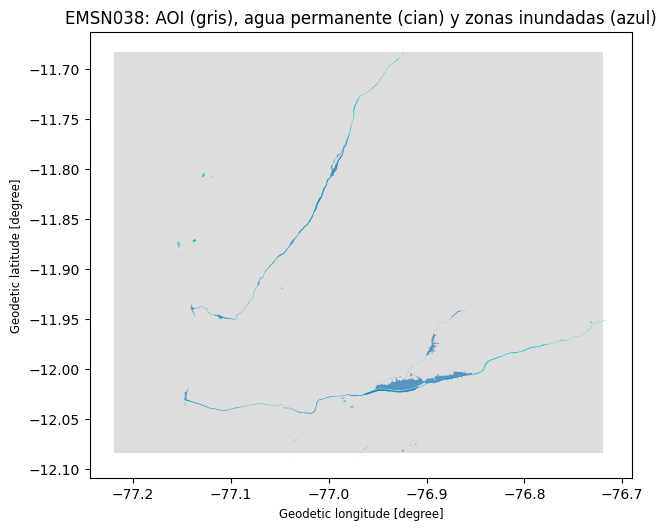

In [ ]:
# Palabras clave (minúsculas, sin "_") para identificar capas por nombre de archivo+capa.
# Capas reales de EMSN038_UTM18S_v0.gdb (ver catálogo de la celda anterior):
#   inundación  -> 'Potential_Maximum_flood'  (producto "Flood Extent" de EMSN038; es extensión máxima POTENCIAL, no un 'observed event')
#   AOI         -> 'EMSN038_AOI'
#   agua perm.  -> 'WatrcrsA' (ríos, polígonos) y 'LakeresA' (lagos/embalses). No se usa 'CoastA' (ambigua).
FLOOD_KEYS = ['potentialmaximumflood']
AOI_KEYS   = ['emsn038aoi']
HYDRO_KEYS = ['watrcrsa', 'lakeresa']
USE_HYDRO  = True      # incluye agua permanente como "agua" (Sen1Floods11 también la etiqueta como agua)

def collect(keys, name=''):
    gs = []
    for f, lname, gtype in catalog:
        if any(k in (os.path.basename(f) + lname).lower().replace('_', '') for k in keys):
            g = gpd.read_file(f, layer=lname)
            if len(g) == 0:
                print(f'  [{name}] capa {lname}: vacía'); continue
            g = g[g.geometry.notna() & g.geometry.geom_type.isin(['Polygon', 'MultiPolygon'])].copy()
            g['geometry'] = shapely.force_2d(g.geometry.values)            # quita Z (p. ej. 'MultiPolygon Z' del AOI)
            g['geometry'] = shapely.make_valid(g.geometry.values)          # repara polígonos inválidos
            g = g[g.geometry.geom_type.isin(['Polygon', 'MultiPolygon'])]  # make_valid puede devolver colecciones
            g = g.set_crs(32718, allow_override=True) if g.crs is None else g.to_crs(4326)   # EMSN038 viene en UTM 18S
            if g.crs.to_epsg() != 4326: g = g.to_crs(4326)
            print(f'  [{name}] capa {lname}: {len(g)} polígonos')
            gs.append(g[['geometry']])
    return gpd.GeoDataFrame(pd.concat(gs, ignore_index=True), crs=4326) if gs else None

flood_gdf, aoi_gdf, hydro_gdf = collect(FLOOD_KEYS, 'inundación'), collect(AOI_KEYS, 'AOI'), collect(HYDRO_KEYS, 'agua perm.')
if flood_gdf is None:
    raise ValueError(f'No se encontró capa de inundación con FLOOD_KEYS={FLOOD_KEYS}. Capas disponibles:\n{cat[["archivo", "capa"]].to_string()}\n'
                     'Ajusta FLOOD_KEYS con parte del nombre de la capa (minúsculas y sin "_").')
if aoi_gdf is None:
    print('AVISO: sin capa AOI; se usa la envolvente de las zonas inundadas (+0.01°) como área con etiqueta conocida.')
    aoi_gdf = gpd.GeoDataFrame(geometry=[flood_gdf.union_all().convex_hull.buffer(0.01)], crs=4326)
if not USE_HYDRO: hydro_gdf = None
print('polígonos inundación:', len(flood_gdf), '| AOI:', len(aoi_gdf), '| hidrografía:', 0 if hydro_gdf is None else len(hydro_gdf))
ax = aoi_gdf.plot(color='#ddd', figsize=(7, 7))
if hydro_gdf is not None: hydro_gdf.plot(ax=ax, color='tab:cyan')
flood_gdf.plot(ax=ax, color='tab:blue', alpha=.7)
ax.set_title('EMSN038: AOI (gris), agua permanente (cian) y zonas inundadas (azul)'); plt.show()


## 4. Chips 512×512 con etiquetas alineadas
- Grilla de chips sin solapamiento sobre el ráster S1 (EPSG:4326, ~10 m).
- Etiqueta del chip: **−1** fuera del AOI de EMS (no se sabe) · **0** dentro del AOI y no inundado · **1** inundado (+ agua permanente si `USE_HYDRO`). Los píxeles sin dato SAR también quedan en −1.
- Se conservan chips con ≥ `MIN_KNOWN` de píxeles con etiqueta conocida y ≥ `MIN_S1` de píxeles SAR válidos.

In [ ]:
SIZE, MIN_KNOWN, MIN_S1 = 512, 0.25, 0.7
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling

def rasterize_chip(gdf, box, tr, shape):
    if gdf is None: return np.zeros(shape, np.uint8)
    idx = gdf.sindex.query(box, predicate='intersects')
    if len(idx) == 0: return np.zeros(shape, np.uint8)
    return rasterize(((g, 1) for g in gdf.geometry.iloc[idx]), out_shape=shape, transform=tr, fill=0, dtype='uint8')

for old in glob.glob(f'{CHIPS}/S1/s1_IW*'): os.remove(old)       # borra chips de la corrida anterior (mal nombrados)
raw_files = sorted(glob.glob(f'{RAW}/s1_*.tif'))
if not raw_files:
    raise FileNotFoundError(f'No hay rásteres Sentinel-1 en {RAW} (s1_YYYYMMDD.tif). Genera al menos uno con: '
                            'Ruta A (GEE, celdas 5-8, requiere acceso al proyecto), Ruta B (HyP3: celda 10 con RUN_HYP3=True) '
                            'o Ruta C (tus propios GeoTIFF VV,VH en dB).')
ref = rasterio.open(raw_files[0])
items_by_date = {}
label_done = {}
for rf in raw_files:
    date = os.path.basename(rf)[3:11]
    src = rasterio.open(rf)
    if (src.height, src.width, src.transform) != (ref.height, ref.width, ref.transform):
        src = WarpedVRT(src, crs=ref.crs, transform=ref.transform, width=ref.width, height=ref.height, resampling=Resampling.bilinear)
    items = []
    for r in range(0, ref.height - SIZE + 1, SIZE):
        for c in range(0, ref.width - SIZE + 1, SIZE):
            win = Window(c, r, SIZE, SIZE)
            x = src.read(window=win).astype(np.float32)
            bad = ~np.isfinite(x).all(0) | (x == 0).all(0)
            if (~bad).mean() < MIN_S1: continue
            tr = ref.window_transform(win)
            lab_p = f'{CHIPS}/Label/label_r{r}_c{c}.tif'
            if (r, c) not in label_done:
                box = shapely.geometry.box(*rasterio.windows.bounds(win, ref.transform))
                aoi = rasterize_chip(aoi_gdf, box, tr, (SIZE, SIZE)).astype(bool)
                fl = rasterize_chip(flood_gdf, box, tr, (SIZE, SIZE)).astype(bool)
                hy = rasterize_chip(hydro_gdf, box, tr, (SIZE, SIZE)).astype(bool)
                lab = np.full((SIZE, SIZE), -1, np.int16)
                lab[aoi] = 0; lab[fl | (hy & aoi)] = 1
                label_done[(r, c)] = (lab >= 0).mean()
                prof = dict(driver='GTiff', height=SIZE, width=SIZE, count=1, dtype='int16', crs=ref.crs, transform=tr, nodata=-1)
                with rasterio.open(lab_p, 'w', **prof) as dst: dst.write(lab[None])
            if label_done[(r, c)] < MIN_KNOWN: continue
            x[:, bad] = np.nan
            s1_p = f'{CHIPS}/S1/s1_{date}_r{r}_c{c}.tif'
            prof = dict(driver='GTiff', height=SIZE, width=SIZE, count=2, dtype='float32', crs=ref.crs, transform=tr, nodata=np.nan)
            with rasterio.open(s1_p, 'w', **prof) as dst: dst.write(x)
            items.append(dict(s1=s1_p, lab=lab_p, w=1.0, src='peru', name=f's1_{date}_r{r}_c{c}', r=r, c=c, date=date))
    items_by_date[date] = items
    print(date, '->', len(items), 'chips')
json.dump(items_by_date, open(f'{PERU}/items.json', 'w'))

20170317 -> 42 chips
20170329 -> 42 chips


## 5. Inferencia y métricas en Lima 2017
Se evalúan **todos los modelos** del notebook 02 (E1–E5), por fecha de adquisición S1, junto con una **línea base clásica**: umbral de Otsu sobre VH por fecha (equivalente a la supervisión débil, sin aprendizaje).

No se reajusta nada con Lima: el umbral es 0.5 y el modelo "ganador" proviene de la **validación de Sen1Floods11**.

In [ ]:
from skimage.filters import threshold_otsu
res_df = pd.read_csv(f'{RES}/results.csv')
model_names = list(res_df.experimento)
atts = {n: n.startswith('E5') for n in model_names}
best_name = res_df.sort_values('val_iou').iloc[-1]['experimento']

def loader_for(items): return DataLoader(FloodDataset(items), batch_size=4, shuffle=False, num_workers=2)
preds = {}
rows = []
for date, items in items_by_date.items():
    if not items: continue
    ld = loader_for(items)
    for n in model_names:
        m = UNet(attention=atts[n]).to(device); m.load_state_dict(torch.load(f'{CKPT}/{n}.pt', map_location=device))
        P, Y, V = predict(m, ld, device)
        preds[(n, date)] = P
        rows.append(dict(modelo=n, fecha=date, **score(P, Y, V)))
    # línea base: Otsu sobre VH (dB) de la fecha
    VH = np.stack([rasterio.open(it['s1']).read(2) for it in items]).astype(np.float32)
    ok = np.isfinite(VH) & V
    thr = threshold_otsu(VH[ok][::20]); Pb = np.where(np.isfinite(VH), (VH < thr).astype(np.float16), 0)
    preds[('otsu_VH', date)] = Pb
    rows.append(dict(modelo=f'otsu_VH (umbral {thr:.1f} dB)', fecha=date, **score(Pb, Y, V)))
    preds[('_YV', date)] = (Y, V)
peru = pd.DataFrame(rows)
display(peru.pivot_table(index='modelo', columns='fecha', values='iou').round(3))
display(peru.round(3)[['modelo', 'fecha', 'iou', 'iou_chip', 'omission', 'commission', 'precision', 'recall', 'n_chips']])
peru.to_csv(f'{RES}/peru_results.csv', index=False)

fecha,20170317,20170329
modelo,,
E1_hand,0.007,0.007
E2_weak,0.002,0.004
E3_weak_then_hand,0.005,0.004
E4_mixed,0.003,0.003
E5_att_hand,0.013,0.009
otsu_VH (umbral -14.9 dB),0.012,0.014


,modelo,fecha,iou,iou_chip,omission,commission,precision,recall,n_chips
0,E1_hand,20170317,0.007,0.008,0.989,0.978,0.022,0.011,42.0
1,E2_weak,20170317,0.002,0.001,0.994,0.997,0.003,0.006,42.0
2,E3_weak_then_hand,20170317,0.005,0.010,0.991,0.990,0.010,0.009,42.0
3,E4_mixed,20170317,0.003,0.004,0.996,0.993,0.007,0.004,42.0
4,E5_att_hand,20170317,0.013,0.014,0.977,0.972,0.028,0.023,42.0
5,otsu_VH (umbral -14.9 dB),20170317,0.012,0.012,0.452,0.988,0.012,0.548,42.0
6,E1_hand,20170329,0.007,0.008,0.992,0.965,0.035,0.008,42.0
7,E2_weak,20170329,0.004,0.002,0.990,0.993,0.007,0.010,42.0
8,E3_weak_then_hand,20170329,0.004,0.008,0.994,0.992,0.008,0.006,42.0
9,E4_mixed,20170329,0.003,0.006,0.996,0.990,0.010,0.004,42.0


### Sensibilidad por **tolerancia de borde**
Como las etiquetas EMS provienen de otra imagen, otra resolución y otra fecha, los bordes de los polígonos son inciertos. Se recalcula la métrica **ignorando una banda de `k` píxeles alrededor de cada borde de la etiqueta**: si el IoU sube mucho, parte del error es desajuste de la referencia y no del modelo.

In [ ]:
from scipy.ndimage import binary_dilation, binary_erosion
def ignore_boundary(Y, V, k):
    V2 = V.copy()
    for i in range(len(Y)):
        y = Y[i].astype(bool)
        if y.any():
            band = binary_dilation(y, iterations=k) & ~binary_erosion(y, iterations=k)
            V2[i] &= ~band
    return V2
rows = []
for date in items_by_date:
    if (('_YV', date)) not in preds: continue
    Y, V = preds[('_YV', date)]
    for k in (0, 2, 5, 10):
        V2 = ignore_boundary(Y, V, k) if k else V
        rows.append(dict(fecha=date, banda_px=k, **{best_name: score(preds[(best_name, date)], Y, V2)['iou'],
                                                      'otsu_VH': score(preds[('otsu_VH', date)], Y, V2)['iou']}))
display(pd.DataFrame(rows).round(3))

,fecha,banda_px,E1_hand,otsu_VH
0,20170317,0,0.007,0.012
1,20170317,2,0.005,0.008
2,20170317,5,0.001,0.005
3,20170317,10,0.000,0.002
4,20170329,0,0.007,0.014
5,20170329,2,0.006,0.009
6,20170329,5,0.001,0.006
7,20170329,10,0.000,0.003


## 6. Visualización (modelo ganador del notebook 02)
Verde = acierto · Rojo = comisión · Azul = omisión · Gris = sin etiqueta conocida.

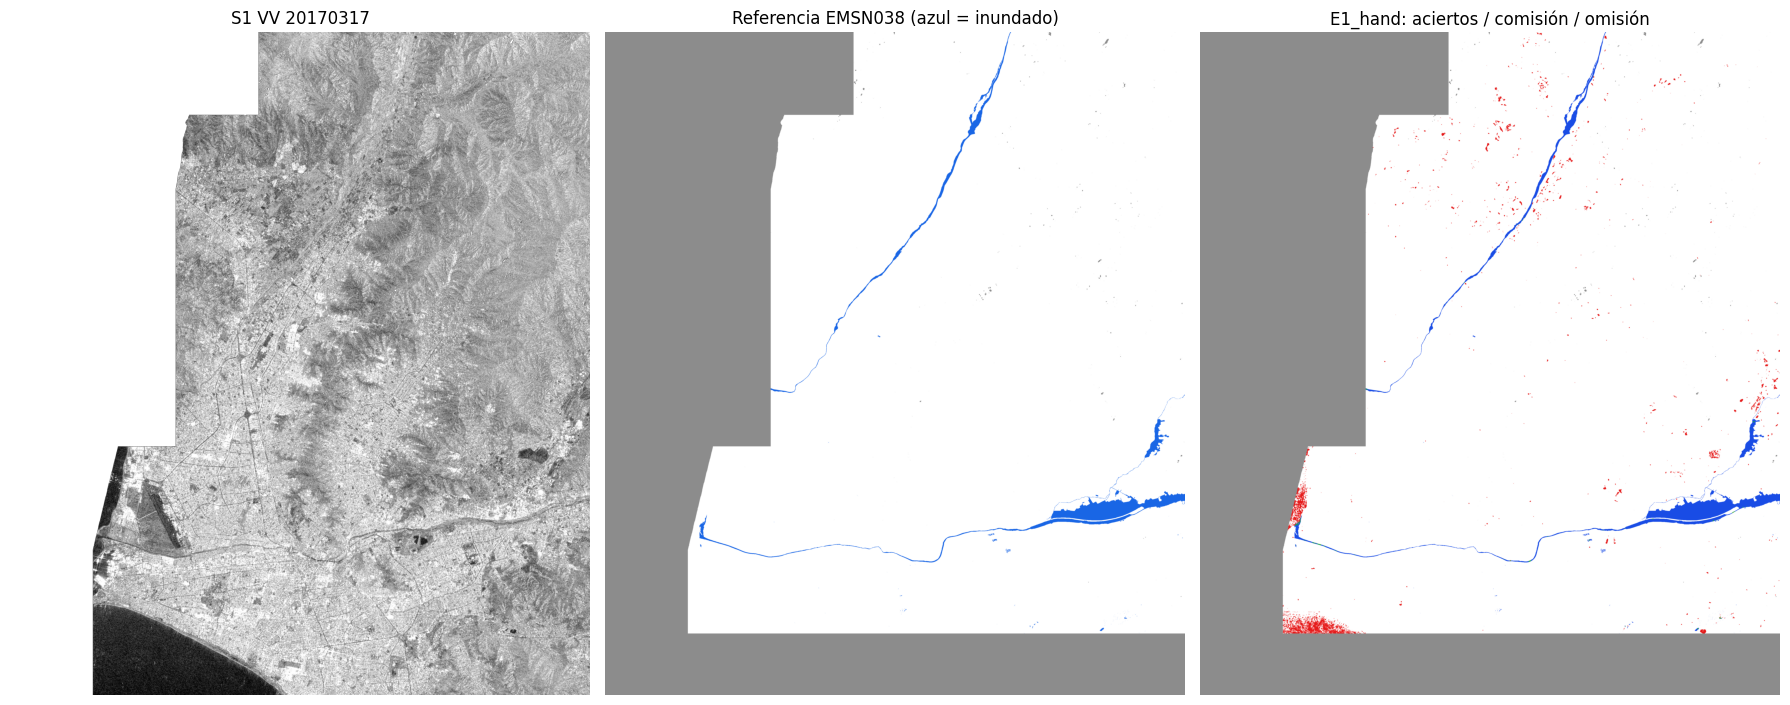

In [ ]:
date_vis = max(items_by_date, key=lambda d: len(items_by_date[d]))
items = items_by_date[date_vis]; P = preds[(best_name, date_vis)]; Y, V = preds[('_YV', date_vis)]
def err_rgb(pred, y, v):
    e = np.ones(pred.shape + (3,), np.float32)
    e[y & pred] = (0.1, 0.7, 0.2); e[~y & pred] = (0.9, 0.1, 0.1); e[y & ~pred] = (0.1, 0.3, 0.9); e[~v] = 0.55
    return e
# mosaico completo
R = max(it['r'] for it in items) + SIZE; C = max(it['c'] for it in items) + SIZE
mos = np.full((R, C, 3), 0.55, np.float32); vv_m = np.full((R, C), np.nan, np.float32); lab_m = np.full((R, C, 3), 0.55, np.float32)
for i, it in enumerate(items):
    r, c = it['r'], it['c']
    mos[r:r + SIZE, c:c + SIZE] = err_rgb(P[i] > 0.5, Y[i].astype(bool), V[i])
    vv_m[r:r + SIZE, c:c + SIZE] = rasterio.open(it['s1']).read(1)
    lab_m[r:r + SIZE, c:c + SIZE] = np.where(V[i][..., None], np.where(Y[i][..., None] > 0, [0.1, 0.4, 0.9], [1, 1, 1]), 0.55)
fig, ax = plt.subplots(1, 3, figsize=(18, 7))
ax[0].imshow(vv_m, cmap='gray', vmin=-25, vmax=0); ax[0].set_title(f'S1 VV {date_vis}')
ax[1].imshow(lab_m); ax[1].set_title('Referencia EMSN038 (azul = inundado)')
ax[2].imshow(mos); ax[2].set_title(f'{best_name}: aciertos / comisión / omisión')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

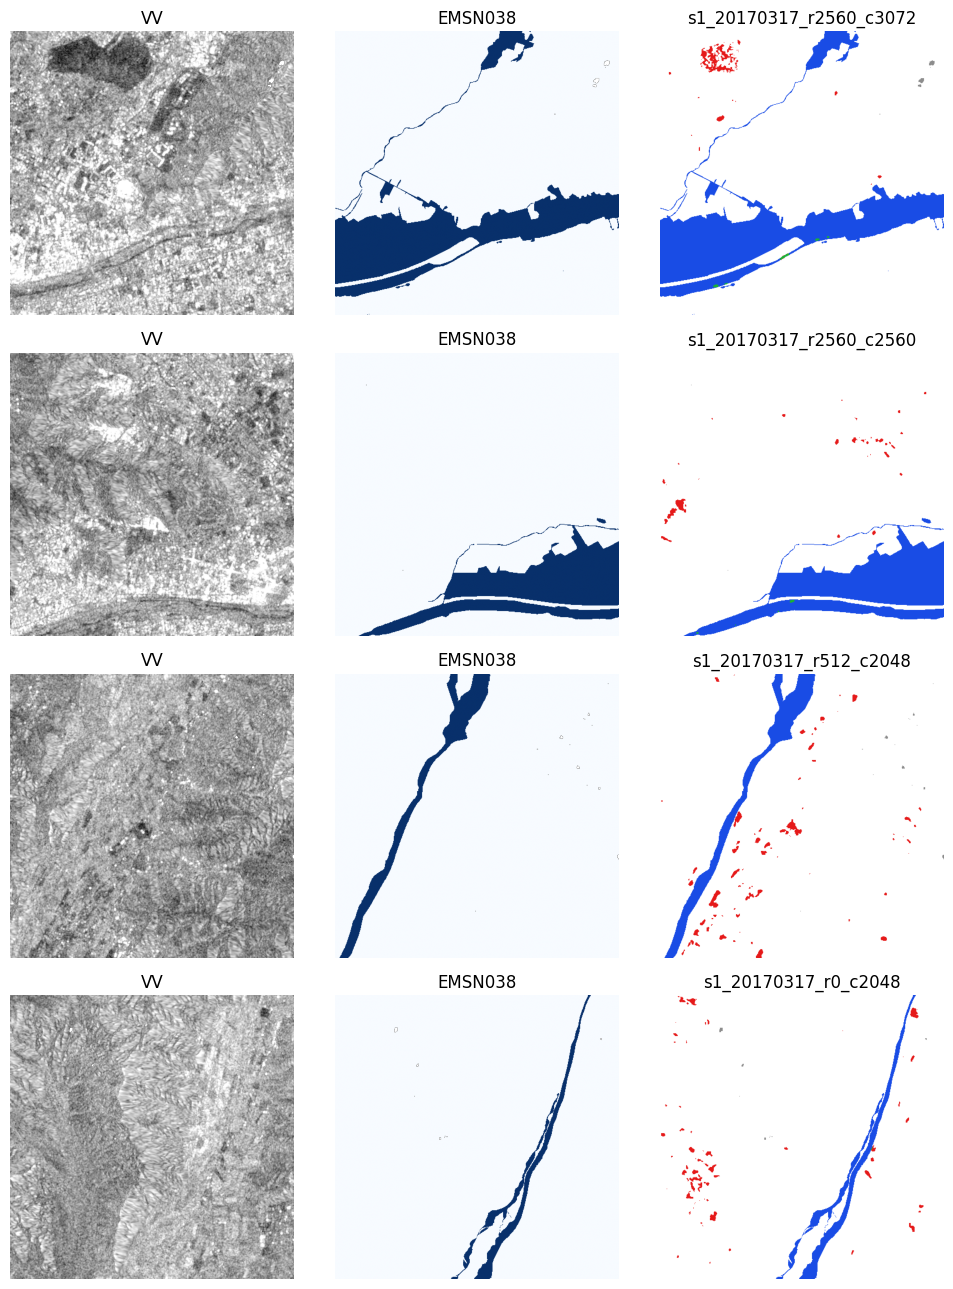

In [ ]:
# Chips individuales con más agua en la referencia
order = np.argsort(-(Y * V).sum((1, 2)).astype(np.int64))[:4]
fig, ax = plt.subplots(4, 3, figsize=(10, 13))
for r, i in enumerate(order):
    s1 = rasterio.open(items[i]['s1']).read()
    ax[r, 0].imshow(s1[0], cmap='gray', vmin=-25, vmax=0); ax[r, 0].set_title('VV')
    ax[r, 1].imshow(np.ma.masked_where(~V[i], Y[i]), cmap='Blues', vmin=0, vmax=1); ax[r, 1].set_title('EMSN038')
    ax[r, 2].imshow(err_rgb(P[i] > 0.5, Y[i].astype(bool), V[i])); ax[r, 2].set_title(items[i]['name'])
for a in ax.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

## 7. Análisis de errores
Retrodispersión de los píxeles según su tipo de acierto/error: ayuda a explicar **por qué** ocurren omisiones (p. ej. agua en zona urbana / vegetación inundada con retorno alto) y comisiones (suelos lisos, arena, sombras de radar).

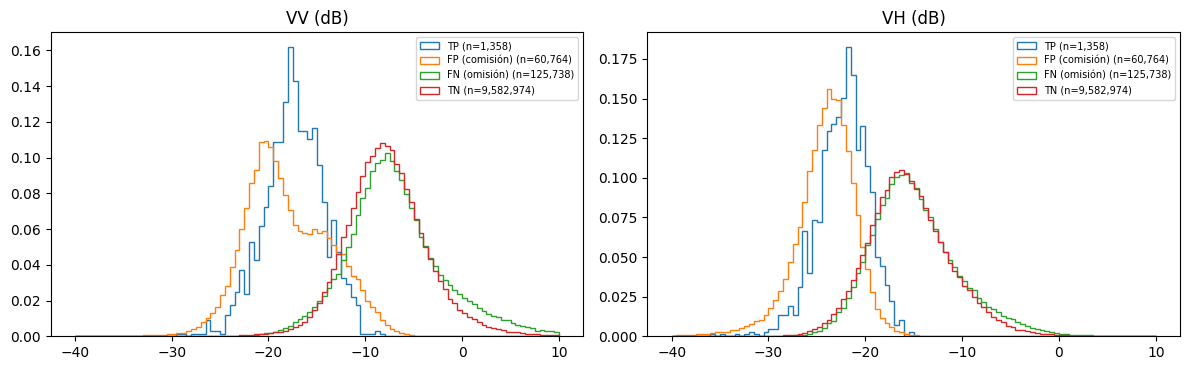

{'TP': '0.01%', 'FP (comisión)': '0.62%', 'FN (omisión)': '1.29%', 'TN': '98.08%'}


In [ ]:
pred = P > 0.5; y = Y.astype(bool)
VVs = np.stack([rasterio.open(it['s1']).read(1) for it in items]); VHs = np.stack([rasterio.open(it['s1']).read(2) for it in items])
groups = {'TP': pred & y & V, 'FP (comisión)': pred & ~y & V, 'FN (omisión)': ~pred & y & V, 'TN': ~pred & ~y & V}
rng = np.random.default_rng(0)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, (arr, nm) in zip(ax, ((VVs, 'VV'), (VHs, 'VH'))):
    for g, m in groups.items():
        v = arr[m & np.isfinite(arr)]
        if len(v): a.hist(rng.choice(v, min(len(v), 200000), replace=False), 100, range=(-40, 10), density=True, histtype='step', label=f'{g} (n={len(v):,})')
    a.set_title(nm + ' (dB)'); a.legend(fontsize=7)
plt.tight_layout(); plt.show()
tot = sum(m.sum() for m in groups.values())
print({g: f'{m.sum() / tot:.2%}' for g, m in groups.items()})

## 8. Documentación de limitaciones (requerida en el informe)

Resume en tu informe, con las cifras de arriba:

1. **Etiquetas de Lima = supervisión débil/ruidosa propia.** Provienen de WorldView-2 (óptico, alta resolución) del 18 y 21/03/2017, con criterio de fotointerpretación distinto al de las etiquetas doradas de Sen1Floods11 (anotación sobre S2 + inspección).
2. **Desfase temporal.** La adquisición S1 usada difiere de las del óptico (ver la tabla de diferencia en días del paso 1). En una inundación urbana el agua evoluciona en horas/días: parte de la comisión/omisión es *desajuste temporal*, no error del modelo.
3. **Desajuste de resolución y geometría.** EMS delinea a alta resolución y con generalización cartográfica; S1 a 10 m con *speckle*. La tabla de **tolerancia de borde** cuantifica ese efecto.
4. **Cobertura parcial de la etiqueta.** Solo hay etiqueta conocida dentro de las AOI de EMS (resto = −1, ignorado). La métrica **no** mide el desempeño fuera de esas AOI.
5. **Entorno urbano.** El agua entre edificios produce *double-bounce* (retorno alto) y suele omitirse; el modelo se entrenó con eventos mayormente rurales/periurbanos (Sen1Floods11).
6. **Agua permanente y costa.** Ríos Rímac/Chillón y el mar pueden contar como "agua" en la predicción; se controla con la capa de hidrografía de EMS (si existe) y las AOI. Verificar si la referencia incluye agua permanente.
7. **Diferencia de preprocesamiento** (si usaste HyP3/SNAP en vez de GEE): puede introducir un desfase radiométrico respecto del dominio de entrenamiento.
8. **Una sola región / evento** → pocas muestras independientes; la incertidumbre es alta y no debe sobre-interpretarse un valor puntual de IoU.
9. **Línea base Otsu** muestra cuánto aporta el aprendizaje (U-Net) frente a un umbral clásico en esta región.

**Extensiones posibles:** *fine-tuning* con una porción espacialmente separada de Lima (evalúa adaptación de dominio), uso de una imagen pre-inundación (diferencia de cambio), y comparación con Bolivia (región de respaldo, notebook 02).

---
# ENTREGABLE 4 · Generalización geográfica al Perú (Lima, marzo 2017)

**Protocolo.** Los modelos E1–E5 se entrenaron **solo con eventos originales de Sen1Floods11** (`sp['train']` + chips débiles de Sen1Floods11; **ningún** dato peruano, y Bolivia excluida). Se evalúan en la región de prueba de Lima construida en este notebook (Sentinel-1 + delineación EMSN038) **sin reajustar nada** (umbral 0,5; modelo ganador elegido en validación de Sen1Floods11).

**Brecha** = IoU en distribución (*test* de Sen1Floods11, Entregable 3) − IoU en Lima. Bolivia (evento nunca visto, partición oficial) se reporta como punto intermedio.

**Regla de viabilidad / respaldo.** Lima es viable si existe una escena S1 a ≤ `MAX_GAP_DAYS` días de alguna fecha de la delineación óptica (18 o 21-mar-2017). Si no, se usa Bolivia y se justifica en el informe.

**Hipótesis que se contrastan con datos (no se asumen):**

| # | Hipótesis | Prueba cuantitativa |
|---|---|---|
| **H1** | Cobertura urbana/terreno de Lima (edificios ⇒ doble rebote, colinas ⇒ sombra, desierto liso) | Métricas por estrato: urbano (EMSN038 `BuiltupA`) vs no urbano; pendiente (DEM) alta vs baja; recall por componente de la etiqueta (inundación vs hidrografía) |
| **H2** | Dominio radiométrico y ángulo de incidencia (HyP3 γ⁰ RTC vs σ⁰ GRD de GEE usado en entrenamiento) | Comparación de distribuciones VV/VH Lima vs Sen1Floods11; **barrido de desplazamiento en dB** (calibración); tendencia de retrodispersión a lo largo del rango; conversión γ⁰→σ⁰ = 10·log₁₀ cos θ |
| **H3** | Desajuste temporal SAR–óptico y naturaleza de la etiqueta (`Potential_Maximum_flood` = extensión **potencial** máxima) | AUC de −VH frente a la etiqueta, % de píxeles “inundados” que parecen agua en SAR, cambio 17→29-mar, **techo** de IoU con umbral óptimo |

In [ ]:
# ===== 4.1 Viabilidad de Lima y fecha principal =====
import importlib
import flood_diag as fd; importlib.reload(fd)            # lo escribe el notebook 02 (sección ENTREGABLES 5-6)
from sklearn.metrics import roc_auc_score
from scipy.stats import wasserstein_distance

MAX_GAP_DAYS = 6          # revisita de Sentinel-1 con A+B en 2017
EMS_DAYS = [pd.Timestamp(d) for d in FLOOD_DAYS]
via = pd.DataFrame([dict(fecha_S1=f'{d[:4]}-{d[4:6]}-{d[6:]}',
                         dif_vs_18mar=(pd.Timestamp(f'{d[:4]}-{d[4:6]}-{d[6:]}') - EMS_DAYS[0]).days,
                         dif_vs_21mar=(pd.Timestamp(f'{d[:4]}-{d[4:6]}-{d[6:]}') - EMS_DAYS[1]).days,
                         chips=len(items_by_date.get(d, []))) for d in DATES])
via['dif_min_abs'] = via[['dif_vs_18mar', 'dif_vs_21mar']].abs().min(axis=1)
display(via)
DATE_MAIN = DATES[int(via.dif_min_abs.values.argmin())]
DATE_CTRL = [d for d in items_by_date if d != DATE_MAIN]
PERU_VIABLE = bool(via.dif_min_abs.min() <= MAX_GAP_DAYS and len(items_by_date.get(DATE_MAIN, [])) > 0)
print(f'Fecha principal: {DATE_MAIN} (|Δ| = {via.dif_min_abs.min()} día(s) respecto de la delineación óptica) | control posterior: {DATE_CTRL}')
print('¿Lima viable?', PERU_VIABLE, '-> región principal:', 'Lima' if PERU_VIABLE else 'BOLIVIA (respaldo: no hay S1 a ≤ %d días; justificar en el informe)' % MAX_GAP_DAYS)
print('Nota: la escena del 29-mar es POSTERIOR al evento (8-11 días): se usa solo como control, no como evaluación principal.')

,fecha_S1,dif_vs_18mar,dif_vs_21mar,chips,dif_min_abs
0,2017-03-17,-1,-4,42,1
1,2017-03-29,11,8,42,8


Fecha principal: 20170317 (|Δ| = 1 día(s) respecto de la delineación óptica) | control posterior: ['20170329']
¿Lima viable? True -> región principal: Lima
Nota: la escena del 29-mar es POSTERIOR al evento (8-11 días): se usa solo como control, no como evaluación principal.


,modelo,test_IoU_en_distribucion,bolivia_IoU,Lima_20170317_IoU,Lima_20170329_IoU,brecha_abs (test − Lima),brecha_rel_%,brecha_abs (Bolivia − Lima)
0,E1_hand,0.6671,0.6475,0.0072,0.0069,0.6599,98.9164,0.6403
1,E2_weak,0.6019,0.7101,0.0021,0.0040,0.5998,99.6543,0.7080
2,E3_weak_then_hand,0.6330,0.6591,0.0047,0.0035,0.6283,99.2521,0.6544
3,E4_mixed,0.6348,0.6436,0.0026,0.0030,0.6322,99.5976,0.6410
4,E5_att_hand,0.6667,0.6491,0.0128,0.0092,0.6539,98.0751,0.6363
5,otsu_VH,NaN,NaN,0.0121,0.0136,NaN,NaN,NaN


Modelo ganador en validación: E1_hand
  IoU test (en distribución) = 0.667 | Bolivia = 0.647 | Lima 20170317 = 0.007  IC95 chips [0.003, 0.016]
  Brecha frente al punto 3: 0.660 puntos de IoU (98.9 % relativo)
  Línea base Otsu-VH en Lima: IoU 0.012 -> la brecha no es solo de la red: un umbral clásico también falla.


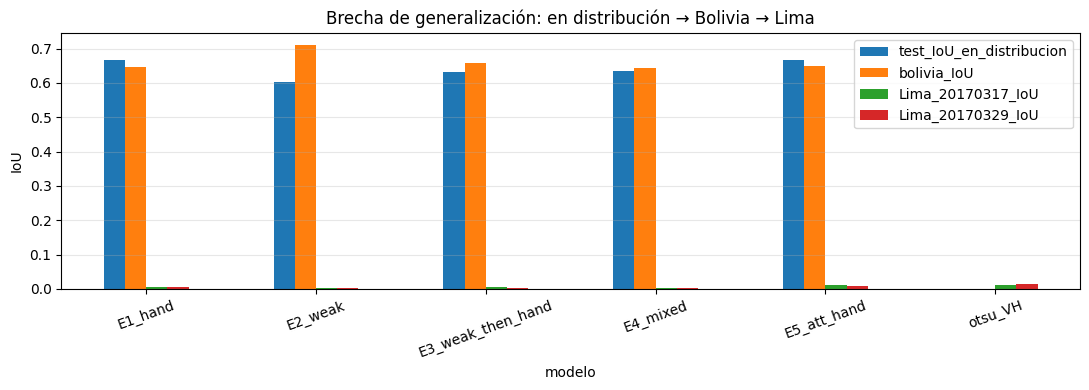

In [ ]:
# ===== 4.2 Brecha de rendimiento frente al punto 3 (test en distribución) =====
def per_chip_counts(P, Y, V, thr=0.5):
    pred = P.astype(np.float32) > thr; y = Y.astype(bool); v = V.astype(bool)
    return np.stack([(pred & y & v).sum((1, 2)), (pred & ~y & v).sum((1, 2)),
                     (~pred & y & v).sum((1, 2)), (~pred & ~y & v).sum((1, 2))], 1).astype(np.int64)
def metrics_from_counts(c):
    tp, fp, fn, tn = [float(x) for x in c]; e = 1e-12
    return dict(iou=tp / (tp + fp + fn + e), f1=2 * tp / (2 * tp + fp + fn + e), precision=tp / (tp + fp + e),
                recall=tp / (tp + fn + e), omission=fn / (tp + fn + e), commission=fp / (tp + fp + e))
def bootstrap_ci(C, B=1000, seed=0, key='iou'):
    rng = np.random.default_rng(seed); n = len(C)
    v = [metrics_from_counts(C[rng.integers(0, n, n)].sum(0))[key] for _ in range(B)]
    return tuple(np.percentile(v, [2.5, 97.5]))

rr = res_df.set_index('experimento')
rows = []
for n in model_names + ['otsu_VH']:
    row = dict(modelo=n, test_IoU_en_distribucion=rr.loc[n, 'test_iou'] if n in rr.index else np.nan,
               bolivia_IoU=rr.loc[n, 'bolivia_iou'] if n in rr.index else np.nan)
    for date in items_by_date:
        Y, V = preds[('_YV', date)]
        row[f'Lima_{date}_IoU'] = metrics_from_counts(per_chip_counts(preds[(n, date)], Y, V).sum(0))['iou']
    rows.append(row)
gap = pd.DataFrame(rows)
gap['brecha_abs (test − Lima)'] = gap.test_IoU_en_distribucion - gap[f'Lima_{DATE_MAIN}_IoU']
gap['brecha_rel_%'] = 100 * gap['brecha_abs (test − Lima)'] / gap.test_IoU_en_distribucion
gap['brecha_abs (Bolivia − Lima)'] = gap.bolivia_IoU - gap[f'Lima_{DATE_MAIN}_IoU']
display(gap.round(4)); gap.to_csv(f'{RES}/entregable4_brecha.csv', index=False)

Yb, Vb = preds[('_YV', DATE_MAIN)]; Cb = per_chip_counts(preds[(best_name, DATE_MAIN)], Yb, Vb)
lo, hi = bootstrap_ci(Cb)
g = gap.set_index('modelo').loc[best_name]
print(f'Modelo ganador en validación: {best_name}')
print(f"  IoU test (en distribución) = {g.test_IoU_en_distribucion:.3f} | Bolivia = {g.bolivia_IoU:.3f} | Lima {DATE_MAIN} = {g[f'Lima_{DATE_MAIN}_IoU']:.3f}  IC95 chips [{lo:.3f}, {hi:.3f}]")
print(f"  Brecha frente al punto 3: {g['brecha_abs (test − Lima)']:.3f} puntos de IoU ({g['brecha_rel_%']:.1f} % relativo)")
base = gap.set_index('modelo').loc[[m for m in gap.modelo if m.startswith('otsu')][0], f'Lima_{DATE_MAIN}_IoU']
print(f'  Línea base Otsu-VH en Lima: IoU {base:.3f} -> la brecha no es solo de la red: un umbral clásico también falla.')
ax = gap.set_index('modelo')[['test_IoU_en_distribucion', 'bolivia_IoU'] + [f'Lima_{d}_IoU' for d in items_by_date]].plot.bar(figsize=(11, 4), rot=20)
ax.set_ylabel('IoU'); ax.set_title('Brecha de generalización: en distribución → Bolivia → Lima'); ax.grid(axis='y', alpha=.3)
plt.tight_layout(); plt.savefig(f'{RES}/entregable4_brecha.png', dpi=170); plt.show()

In [ ]:
# ===== 4.3 Preparar diagnósticos: máscaras por tipo de etiqueta, urbano y pendiente (misma grilla que los chips) =====
builtup_gdf = collect(['builtupa'], 'urbano (BuiltupA)')
COMMON = sorted(set.intersection(*[{(it['r'], it['c']) for it in its} for its in items_by_date.values() if its]))
print('chips comunes a todas las fechas:', len(COMMON))
os.makedirs(f'{PERU}/slope_cache', exist_ok=True)

def lima_masks(it):
    with rasterio.open(it['s1']) as d: tr, bnd = d.transform, d.bounds
    box = shapely.geometry.box(*bnd); shp = (SIZE, SIZE)
    aoi = rasterize_chip(aoi_gdf, box, tr, shp).astype(bool)
    fl = rasterize_chip(flood_gdf, box, tr, shp).astype(bool) & aoi
    hy = rasterize_chip(hydro_gdf, box, tr, shp).astype(bool) & aoi & ~fl
    bu = rasterize_chip(builtup_gdf, box, tr, shp).astype(bool) if builtup_gdf is not None else np.zeros(shp, bool)
    f = f"{PERU}/slope_cache/r{it['r']}_c{it['c']}.npy"
    if os.path.exists(f): a = np.load(f); sl = None if a.size == 1 else a
    else:
        sl = fd.dem_slope(it['s1']); np.save(f, sl if sl is not None else np.zeros(1, np.float32))
    return fl, hy, bu, (sl if sl is not None else np.full(shp, np.nan, np.float32))

by_rc = {(it['r'], it['c']): it for it in items_by_date[DATE_MAIN]}
M = [lima_masks(by_rc[rc]) for rc in COMMON]
FL, HY, BU, SL = [np.stack([m[k] for m in M]) for k in range(4)]
print('DEM disponible en', int(np.isfinite(SL).any((1, 2)).sum()), 'de', len(COMMON), 'chips')

L = {}                                       # arrays alineados por (r,c) para cada fecha
for date, its in items_by_date.items():
    imap = {(it['r'], it['c']): k for k, it in enumerate(its)}; ix_ = [imap[rc] for rc in COMMON]
    Yd, Vd = preds[('_YV', date)]
    s1 = np.stack([rasterio.open(its[k]['s1']).read() for k in ix_]).astype(np.float32)
    L[date] = dict(VV=s1[:, 0], VH=s1[:, 1], Y=Yd[ix_].astype(bool), V=Vd[ix_].astype(bool),
                   P=preds[(best_name, date)][ix_].astype(np.float32))
Lm = L[DATE_MAIN]; PRm = Lm['P'] > 0.5
EVID = {}
print('píxeles válidos:', int(Lm['V'].sum()), '| % agua en referencia:', f"{(Lm['Y'] & Lm['V']).sum() / Lm['V'].sum():.2%}",
      '| % predicho agua:', f"{(PRm & Lm['V']).sum() / Lm['V'].sum():.2%}")
print('de la etiqueta de agua: inundación (Potential_Maximum_flood) =', int((FL & Lm['V']).sum()), 'px | hidrografía permanente =', int((HY & Lm['V']).sum()), 'px')

  [urbano (BuiltupA)] capa BuiltupA: 437 polígonos
chips comunes a todas las fechas: 42
DEM disponible en 42 de 42 chips
píxeles válidos: 9770834 | % agua en referencia: 1.30% | % predicho agua: 0.64%
de la etiqueta de agua: inundación (Potential_Maximum_flood) = 121408 px | hidrografía permanente = 5688 px


In [ ]:
# ===== H1 · Cobertura del suelo: urbano / pendiente / componente de la etiqueta =====
def strat(name, m):
    m = Lm['V'] & m; Y_, pr = Lm['Y'], PRm
    tp, fp, fn = (pr & Y_ & m).sum(), (pr & ~Y_ & m).sum(), (~pr & Y_ & m).sum(); e = 1e-9
    return dict(estrato=name, px_validos=int(m.sum()), pct_agua_ref=100 * (Y_ & m).sum() / max(m.sum(), 1),
                pct_pred_agua=100 * pr[m].mean() if m.any() else np.nan, recall=tp / (tp + fn + e), precision=tp / (tp + fp + e),
                IoU=tp / (tp + fp + fn + e), FP=int(fp), FN=int(fn))
steep = np.nan_to_num(SL, nan=0) >= 8
h1 = pd.DataFrame([strat('todo', np.ones_like(BU)), strat('urbano (BuiltupA)', BU), strat('no urbano', ~BU),
                   strat('pendiente ≥ 8°', steep), strat('pendiente < 8°', ~steep),
                   strat('urbano ∩ llano', BU & ~steep), strat('no urbano ∩ llano', ~BU & ~steep)])
display(h1.round(4)); h1.to_csv(f'{RES}/entregable4_H1_estratos.csv', index=False)

rec_fl = (PRm & FL & Lm['V']).sum() / max((FL & Lm['V']).sum(), 1); rec_hy = (PRm & HY & Lm['V']).sum() / max((HY & Lm['V']).sum(), 1)
fp_all = (PRm & ~Lm['Y'] & Lm['V']); fn_all = (~PRm & Lm['Y'] & Lm['V'])
EVID['H1_recall_inundacion_potencial'] = rec_fl; EVID['H1_recall_hidrografia_perm'] = rec_hy
EVID['H1_pct_FP_en_urbano'] = 100 * (fp_all & BU).sum() / max(fp_all.sum(), 1); EVID['H1_pct_FP_en_pendiente>=8'] = 100 * (fp_all & steep).sum() / max(fp_all.sum(), 1)
EVID['H1_pct_FN_en_urbano'] = 100 * (fn_all & BU).sum() / max(fn_all.sum(), 1); EVID['H1_pct_area_urbana'] = 100 * (BU & Lm['V']).sum() / Lm['V'].sum()
print(f'Recall sobre polígonos de INUNDACIÓN (potencial máx.): {rec_fl:.3f} | sobre HIDROGRAFÍA permanente (WatrcrsA/LakeresA): {rec_hy:.3f}')
print(f"% del FP en zona urbana: {EVID['H1_pct_FP_en_urbano']:.1f} % (área urbana = {EVID['H1_pct_area_urbana']:.1f} % de los píxeles) | % del FP con pendiente ≥ 8°: {EVID['H1_pct_FP_en_pendiente>=8']:.1f} %")
print(f"% del FN en zona urbana: {EVID['H1_pct_FN_en_urbano']:.1f} %")
print('Lectura: si el recall en hidrografía permanente (agua inequívoca) es alto y en inundación es ~0, el problema es la etiqueta/fecha (H3), no la cobertura.')

,estrato,px_validos,pct_agua_ref,pct_pred_agua,recall,precision,IoU,FP,FN
0,todo,9770834,1.3008,0.6358,0.0107,0.0219,0.0072,60764,125738
1,urbano (BuiltupA),4775422,1.4378,0.1376,0.0045,0.0470,0.0041,6260,68351
2,no urbano,4995412,1.1698,1.1121,0.0180,0.0189,0.0093,54504,57387
3,pendiente ≥ 8°,4118700,0.0611,0.2322,0.0155,0.0041,0.0032,9525,2478
4,pendiente < 8°,5652134,2.2041,0.9299,0.0106,0.0251,0.0075,51239,123260
5,urbano ∩ llano,4006693,1.6784,0.1541,0.0041,0.0449,0.0038,5898,66971
6,no urbano ∩ llano,1645441,3.4842,2.8189,0.0182,0.0225,0.0101,45341,56289


Recall sobre polígonos de INUNDACIÓN (potencial máx.): 0.010 | sobre HIDROGRAFÍA permanente (WatrcrsA/LakeresA): 0.030
% del FP en zona urbana: 10.3 % (área urbana = 48.9 % de los píxeles) | % del FP con pendiente ≥ 8°: 15.7 %
% del FN en zona urbana: 54.4 %
Lectura: si el recall en hidrografía permanente (agua inequívoca) es alto y en inundación es ~0, el problema es la etiqueta/fecha (H3), no la cobertura.


$ gsutil -m -q rsync -r gs://sen1floods11/v1.1/data/flood_events/HandLabeled/S1Hand /content/sen1floods11/HandLabeled/S1Hand
$ gsutil -m -q rsync -r gs://sen1floods11/v1.1/data/flood_events/HandLabeled/LabelHand /content/sen1floods11/HandLabeled/LabelHand
$ gsutil -m -q cp -r gs://sen1floods11/v1.1/splits/flood_handlabeled /content/sen1floods11/splits/


,clase,banda,Lima_p5,Lima_p50,Lima_p95,S1F11_p5,S1F11_p50,S1F11_p95,dif_mediana_dB,wasserstein_dB
0,no agua (ref=0),VV,-14.380000,-7.98,-0.59,-15.370000,-9.400000,-4.84,1.42,1.81
1,no agua (ref=0),VH,-22.059999,-15.78,-7.96,-22.510000,-15.830000,-11.36,0.05,0.90
2,agua (ref=1),VV,-14.930000,-7.45,2.95,-24.420000,-15.000000,-7.40,7.56,8.66
3,agua (ref=1),VH,-21.559999,-15.43,-6.32,-36.200001,-25.139999,-15.19,9.71,10.32


,shift_dB,IoU_Lima,IoU_control_S1F11
0,-6,0.0084,0.5033
1,-4,0.0096,0.5830
2,-2,0.0103,0.6258
3,0,0.0072,0.6506
4,2,0.0012,0.6219
5,4,0.0001,0.4285
6,6,0.0000,0.2165


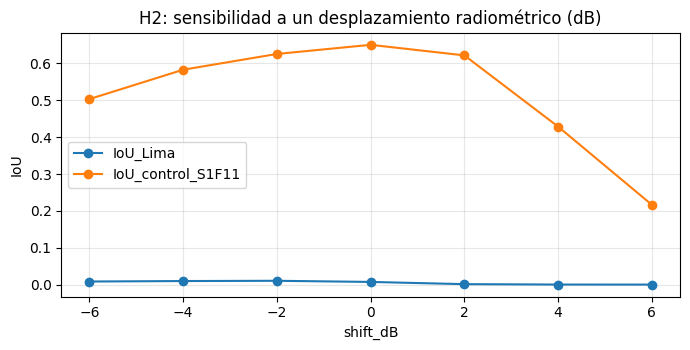

Si un desplazamiento de unos dB elevara mucho el IoU de Lima (y el control tuviera su máximo en 0), la calibración/ángulo (γ⁰ vs σ⁰) explica parte de la brecha. Si ni así sube, la causa es otra (H1/H3).


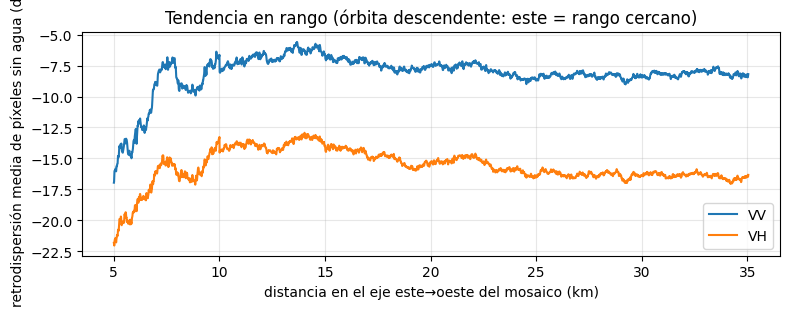

Tendencia: VV +0.34 dB/10 km, VH -0.26 dB/10 km a lo largo de ~30 km
 ángulo_incidencia_°  γ⁰→σ⁰ (dB) = 10·log10(cos θ)
                  30                         -0.62
                  35                         -0.87
                  40                         -1.16
                  45                         -1.51
Nota: no se exportó el ráster de ángulo de incidencia (HyP3 con include_inc_map=True o la banda `angle` de GEE lo darían); aquí el ángulo se contrasta solo de forma indirecta.


In [ ]:
# ===== H2 · Dominio radiométrico (γ⁰ RTC de HyP3 vs σ⁰ GRD de GEE) e incidencia =====
def ensure_hand_data():
    hl = f'{fu.LOCAL}/HandLabeled'
    for d in ('S1Hand', 'LabelHand'):
        if not (os.path.isdir(f'{hl}/{d}') and len(os.listdir(f'{hl}/{d}')) >= 446):
            os.makedirs(f'{hl}/{d}', exist_ok=True)
            fu.sh(f'gsutil -m -q rsync -r {fu.GCS}/data/flood_events/HandLabeled/{d} {hl}/{d}')
    if not os.path.isdir(f'{fu.LOCAL}/splits/flood_handlabeled'):
        os.makedirs(f'{fu.LOCAL}/splits', exist_ok=True)
        fu.sh(f'gsutil -m -q cp -r {fu.GCS}/splits/flood_handlabeled {fu.LOCAL}/splits/')
ensure_hand_data()
import random
sp_ = fu.load_hand_splits(); ctrl = random.Random(0).sample(sp_['test'], 40)                      # control: chips de test de Sen1Floods11
CV, CH_, CY, CVal = [], [], [], []
for it in ctrl:
    with rasterio.open(it['s1']) as d: a = d.read().astype(np.float32)
    with rasterio.open(it['lab']) as d: l = d.read(1)
    CV.append(a[0]); CH_.append(a[1]); CY.append(l == 1); CVal.append((l >= 0) & np.isfinite(a).all(0))
CV, CH_, CY, CVal = map(np.stack, (CV, CH_, CY, CVal))

rng = np.random.default_rng(0)
def smp(a, m, n=200000):
    v = a[m & np.isfinite(a)]; return rng.choice(v, min(n, len(v)), replace=False)
rows = []
for cls, mL, mC in (('no agua (ref=0)', Lm['V'] & ~Lm['Y'], CVal & ~CY), ('agua (ref=1)', Lm['V'] & Lm['Y'], CVal & CY)):
    for b, aL, aC in (('VV', Lm['VV'], CV), ('VH', Lm['VH'], CH_)):
        l_, c_ = smp(aL, mL), smp(aC, mC)
        rows.append(dict(clase=cls, banda=b, **{f'Lima_p{q}': np.percentile(l_, q) for q in (5, 50, 95)},
                         **{f'S1F11_p{q}': np.percentile(c_, q) for q in (5, 50, 95)},
                         dif_mediana_dB=np.median(l_) - np.median(c_), wasserstein_dB=wasserstein_distance(l_, c_)))
h2a = pd.DataFrame(rows).round(2); display(h2a); h2a.to_csv(f'{RES}/entregable4_H2_distribuciones.csv', index=False)
EVID['H2_dif_mediana_VV_noagua_dB'] = float(h2a.query("clase=='no agua (ref=0)' and banda=='VV'").dif_mediana_dB.iloc[0])
EVID['H2_dif_mediana_VH_noagua_dB'] = float(h2a.query("clase=='no agua (ref=0)' and banda=='VH'").dif_mediana_dB.iloc[0])

@torch.no_grad()
def predict_raw(model, X, bs=4):                      # X: (N,2,H,W) en dB, misma normalización que FloodDataset
    model.eval(); out = []
    for k in range(0, len(X), bs):
        xs, bads = zip(*[fu.normalize_s1(x) for x in X[k:k + bs]])
        xb = np.stack([a * (~b)[None] for a, b in zip(xs, bads)])
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == 'cuda'):
            out.append(torch.sigmoid(model(torch.from_numpy(xb).to(device))).float()[:, 0].cpu().numpy())
    return np.concatenate(out)
best = UNet(attention=atts[best_name]).to(device); best.load_state_dict(torch.load(f'{CKPT}/{best_name}.pt', map_location=device))
XL = np.stack([Lm['VV'], Lm['VH']], 1); XC = np.stack([CV, CH_], 1)
sw = []
for dlt in range(-6, 7, 2):                           # desplazamiento radiométrico aplicado a VV y VH
    sw.append(dict(shift_dB=dlt,
                   IoU_Lima=score(predict_raw(best, XL + dlt), Lm['Y'].astype(np.uint8), Lm['V'])['iou'],
                   IoU_control_S1F11=score(predict_raw(best, XC + dlt), CY.astype(np.uint8), CVal)['iou']))
sw = pd.DataFrame(sw); display(sw.round(4)); sw.to_csv(f'{RES}/entregable4_H2_barrido_dB.csv', index=False)
EVID['H2_IoU_Lima_sin_shift'] = float(sw.query('shift_dB==0').IoU_Lima.iloc[0]); EVID['H2_IoU_Lima_mejor_shift'] = float(sw.IoU_Lima.max())
EVID['H2_mejor_shift_dB'] = int(sw.loc[sw.IoU_Lima.idxmax(), 'shift_dB'])
ax = sw.set_index('shift_dB').plot(marker='o', figsize=(7, 3.6)); ax.set_ylabel('IoU'); ax.set_title('H2: sensibilidad a un desplazamiento radiométrico (dB)'); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
print('Si un desplazamiento de unos dB elevara mucho el IoU de Lima (y el control tuviera su máximo en 0), la calibración/ángulo (γ⁰ vs σ⁰) explica parte de la brecha. '
      'Si ni así sube, la causa es otra (H1/H3).')

# --- tendencia de retrodispersión a lo largo del mosaico (proxy del ángulo de incidencia en rango) ---
Wm = max(it['c'] for it in items_by_date[DATE_MAIN]) + SIZE
s_vv, s_vh, cnt = np.zeros(Wm), np.zeros(Wm), np.zeros(Wm)
for k, rc in enumerate(COMMON):
    m = Lm['V'][k] & ~Lm['Y'][k]; c0 = rc[1]
    s_vv[c0:c0 + SIZE] += np.where(m, np.nan_to_num(Lm['VV'][k]), 0).sum(0); s_vh[c0:c0 + SIZE] += np.where(m, np.nan_to_num(Lm['VH'][k]), 0).sum(0); cnt[c0:c0 + SIZE] += m.sum(0)
ok = cnt > 500; km = np.arange(Wm) * 0.00978              # 1 px ≈ 9.8 m en longitud a -12°
pv, ph = np.polyfit(km[ok], (s_vv / np.maximum(cnt, 1))[ok], 1), np.polyfit(km[ok], (s_vh / np.maximum(cnt, 1))[ok], 1)
EVID['H2_pendiente_VV_dB_por_10km'] = 10 * pv[0]; EVID['H2_pendiente_VH_dB_por_10km'] = 10 * ph[0]
fig, ax = plt.subplots(figsize=(8, 3.2)); ax.plot(km[ok], (s_vv / np.maximum(cnt, 1))[ok], label='VV'); ax.plot(km[ok], (s_vh / np.maximum(cnt, 1))[ok], label='VH')
ax.set_xlabel('distancia en el eje este→oeste del mosaico (km)'); ax.set_ylabel('retrodispersión media de píxeles sin agua (dB)'); ax.legend(); ax.grid(alpha=.3)
ax.set_title('Tendencia en rango (órbita descendente: este = rango cercano)'); plt.tight_layout(); plt.show()
print(f"Tendencia: VV {10 * pv[0]:+.2f} dB/10 km, VH {10 * ph[0]:+.2f} dB/10 km a lo largo de ~{km[ok].max() - km[ok].min():.0f} km")
print(pd.DataFrame({'ángulo_incidencia_°': [30, 35, 40, 45], 'γ⁰→σ⁰ (dB) = 10·log10(cos θ)': [round(10 * np.log10(np.cos(np.radians(t))), 2) for t in (30, 35, 40, 45)]}).to_string(index=False))
print('Nota: no se exportó el ráster de ángulo de incidencia (HyP3 con include_inc_map=True o la banda `angle` de GEE lo darían); aquí el ángulo se contrasta solo de forma indirecta.')

In [ ]:
# ===== H3 · Desajuste temporal y naturaleza de la etiqueta: ¿la etiqueta es visible en el SAR? =====
rows = []
vh_water_thr = np.percentile(CH_[CVal & CY & np.isfinite(CH_)], 90)       # VH por debajo del cual está el 90 % del agua de Sen1Floods11 (control)
print(f'Umbral VH tipo-agua (percentil 90 del agua en Sen1Floods11): {vh_water_thr:.1f} dB')
def auc(pos, neg, a, n=300000):
    p, q = smp(-a, pos, n), smp(-a, neg, n)
    return roc_auc_score(np.r_[np.ones(len(p)), np.zeros(len(q))], np.r_[p, q])
for date in sorted(L):
    d = L[date]; neg = d['V'] & ~d['Y']
    for nm, pos in (('inundación (potencial máx.)', FL & d['V']), ('hidrografía permanente', HY & d['V'])):
        rows.append(dict(fecha=date, componente_ref=nm, px=int(pos.sum()), AUC_menosVH=auc(pos, neg, d['VH']),
                         pct_con_VH_tipo_agua=100 * (d['VH'][pos] < vh_water_thr).mean(),
                         pct_fondo_con_VH_tipo_agua=100 * (d['VH'][neg & np.isfinite(d['VH'])] < vh_water_thr).mean()))
h3 = pd.DataFrame(rows); display(h3.round(3)); h3.to_csv(f'{RES}/entregable4_H3_visibilidad_SAR.csv', index=False)
for _, r in h3.iterrows(): EVID[f"H3_AUC[{r.fecha}|{r.componente_ref[:10]}]"] = r.AUC_menosVH

# cambio entre las dos fechas dentro de los polígonos de inundación
ds = sorted(L)
if len(ds) >= 2:
    dV = L[ds[1]]['VH'] - L[ds[0]]['VH']; okc = np.isfinite(dV) & L[ds[0]]['V']
    in_fl, out_fl = okc & FL, okc & ~L[ds[0]]['Y']
    EVID['H3_dVH_medio_en_inundacion'] = float(dV[in_fl].mean()); EVID['H3_dVH_medio_fondo'] = float(dV[out_fl].mean())
    print(f"ΔVH ({ds[1]} − {ds[0]}): en polígonos de inundación {dV[in_fl].mean():+.2f} dB | fondo {dV[out_fl].mean():+.2f} dB | "
          f"% de inundación con ΔVH > +3 dB (agua que desaparece): {100 * (dV[in_fl] > 3).mean():.1f} %")

# techo: mejor umbral posible (diagnóstico con oráculo, NO es un resultado de generalización)
def iou_thr(pred, d):
    tp, fp, fn = (pred & d['Y'] & d['V']).sum(), (pred & ~d['Y'] & d['V']).sum(), (~pred & d['Y'] & d['V']).sum(); return tp / (tp + fp + fn + 1e-9)
d = L[DATE_MAIN]
ceil_vh = max((iou_thr(np.nan_to_num(d['VH'], nan=0) < t, d), t) for t in np.arange(-32, -6, 1.0))
ceil_p = max((iou_thr(d['P'] > t, d), t) for t in (0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9))
EVID['H3_techo_IoU_umbral_VH'] = ceil_vh[0]; EVID['H3_techo_IoU_umbral_prob_modelo'] = ceil_p[0]
print(f'Techo con oráculo en Lima {DATE_MAIN}: umbral de VH óptimo ({ceil_vh[1]:.0f} dB) -> IoU {ceil_vh[0]:.3f} | umbral de prob. óptimo ({ceil_p[1]}) -> IoU {ceil_p[0]:.3f}')
print('Si el techo también es ~0, ningún clasificador basado en este SAR puede reproducir esta etiqueta: el cuello de botella es la referencia (fecha/tipo de producto), no el modelo.')

Umbral VH tipo-agua (percentil 90 del agua en Sen1Floods11): -16.9 dB


,fecha,componente_ref,px,AUC_menosVH,pct_con_VH_tipo_agua,pct_fondo_con_VH_tipo_agua
0,20170317,inundación (potencial máx.),121408,0.465,34.279,37.951
1,20170317,hidrografía permanente,5688,0.586,44.761,37.951
2,20170329,inundación (potencial máx.),121408,0.513,39.073,35.652
3,20170329,hidrografía permanente,5688,0.618,48.207,35.652


ΔVH (20170329 − 20170317): en polígonos de inundación -0.50 dB | fondo +0.22 dB | % de inundación con ΔVH > +3 dB (agua que desaparece): 11.2 %
Techo con oráculo en Lima 20170317: umbral de VH óptimo (-7 dB) -> IoU 0.013 | umbral de prob. óptimo (0.02) -> IoU 0.015
Si el techo también es ~0, ningún clasificador basado en este SAR puede reproducir esta etiqueta: el cuello de botella es la referencia (fecha/tipo de producto), no el modelo.


In [ ]:
# ===== Resumen de evidencias (alimenta la redacción del informe) =====
ev = pd.Series(EVID, name='valor').round(4).to_frame(); display(ev); ev.to_csv(f'{RES}/entregable4_evidencias.csv')

,valor
H1_recall_inundacion_potencial,0.0098
H1_recall_hidrografia_perm,0.0299
H1_pct_FP_en_urbano,10.3022
H1_pct_FP_en_pendiente>=8,15.6754
H1_pct_FN_en_urbano,54.3599
H1_pct_area_urbana,48.8743
H2_dif_mediana_VV_noagua_dB,1.4200
H2_dif_mediana_VH_noagua_dB,0.0500
H2_IoU_Lima_sin_shift,0.0072
H2_IoU_Lima_mejor_shift,0.0103


### Cómo interpretar las pruebas (reglas decididas **antes** de mirar los números)

| Hipótesis | La **apoya** si… | La **refuta / limita** si… |
|---|---|---|
| **H1 · cobertura urbana/terreno** | el IoU/recall en `urbano` o `pendiente ≥ 8°` es claramente menor que en el resto, o el % del FP/FN en esos estratos supera con holgura su % de área | el rendimiento es igualmente bajo en estratos llanos y no urbanos |
| **H2 · radiometría / incidencia** | un desplazamiento de pocos dB eleva el IoU de Lima (y el control de Sen1Floods11 sigue con máximo en 0); la mediana de píxeles sin agua difiere ≥ 1–2 dB de Sen1Floods11 | el barrido no cambia el IoU y las distribuciones de fondo coinciden |
| **H3 · desajuste temporal / etiqueta** | AUC(−VH) ≈ 0,5 en la componente “inundación”, pocos píxeles de inundación con VH tipo-agua, techo con umbral óptimo ≈ 0, mientras la hidrografía permanente sí es detectable (AUC alto, recall alto) | la inundación es claramente visible en el SAR (AUC ≫ 0,5) pero el modelo la pierde |

**Notas para el informe.**
- La capa usada es `Potential_Maximum_flood`: extensión **potencial máxima** delineada con óptico (18/21-mar), no una huella observada en la fecha del SAR. Esto, más el desfase de 1 día (17-mar) a 11 días (29-mar), hace que parte de la “brecha” sea de la referencia y no del modelo.
- Otras causas a nombrar si los datos las respaldan: coberturas inexistentes en el entrenamiento (desierto costero liso, colinas áridas, edificación densa), preprocesamiento HyP3 γ⁰ vs GEE σ⁰, y escenas con 80 % de cobertura útil (bordes sin dato).
- Una sola región/evento y pocos chips ⇒ cualquier IoU es una estimación muy incierta; los IC por bootstrap de chips subestiman la incertidumbre real.
- Bolivia como respaldo: **no** hace falta si `PERU_VIABLE = True` (escena S1 a 1 día de la delineación óptica); se reporta igualmente como punto intermedio de generalización.

---
## ENTREGABLE 5 (complemento) · Fallos característicos del SAR en Lima

En el notebook 02 se analizan los fallos con etiquetas doradas y S2. Aquí se repite la minería sobre Lima con lo que sí hay: **pendiente (DEM)** y **zonas edificadas (EMSN038 `BuiltupA`)**. Como la referencia de Lima es débil (H3), cada hallazgo se interpreta con cautela: un FN en zona urbana con VV alto es *compatible* con doble rebote, pero también con que la etiqueta potencial no corresponda a agua visible en esa fecha.

,tipo,pixeles,pct_del_FP_o_FN
0,FN_doble_rebote_urb,58696,46.68
1,FN_retorno_alto_otro,41815,33.26
2,FP_sombra_terreno,2990,4.92


FP totales 60,764 | FN totales 125,738


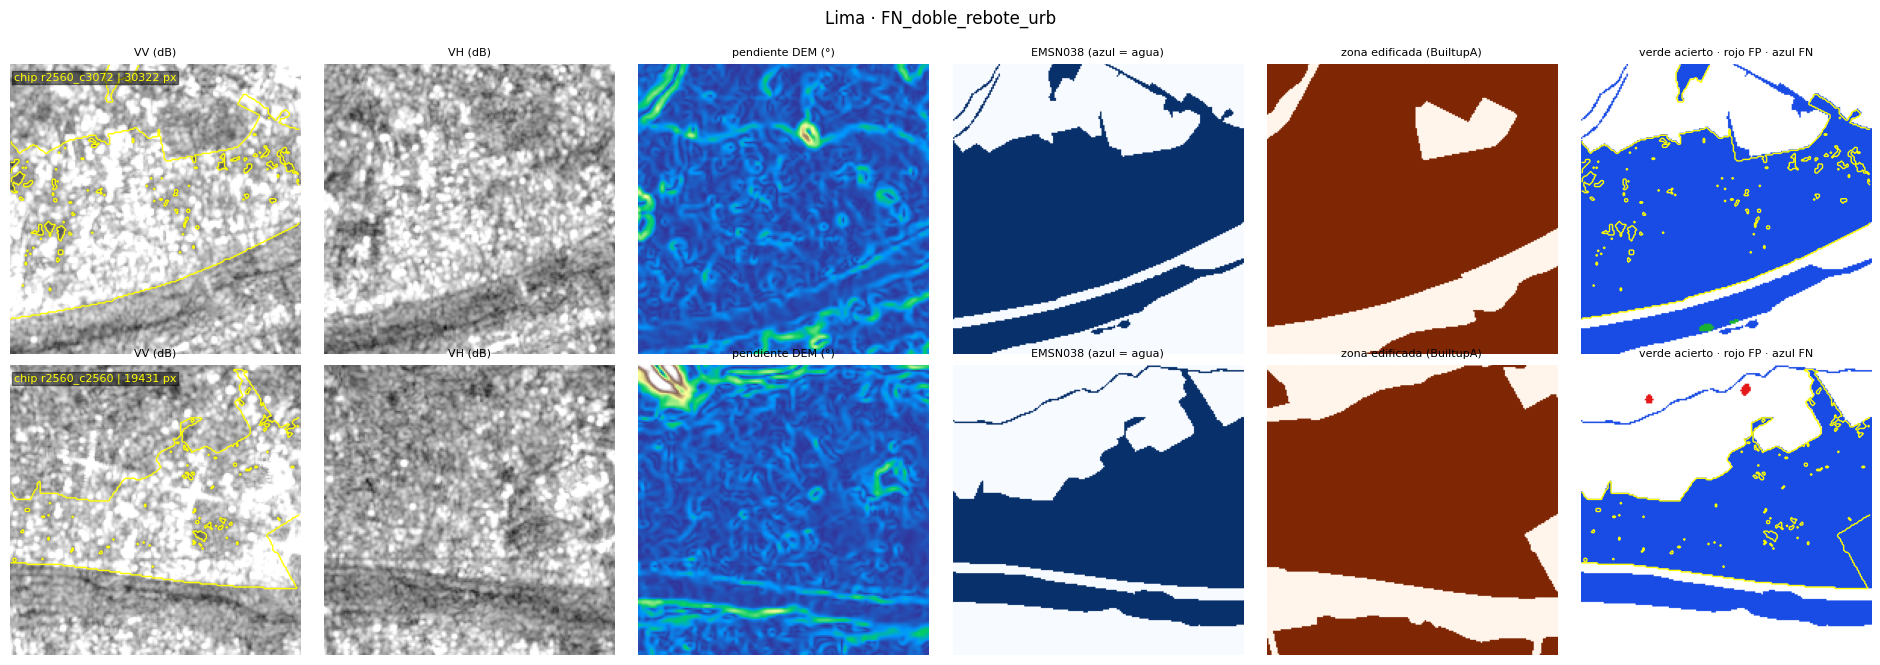

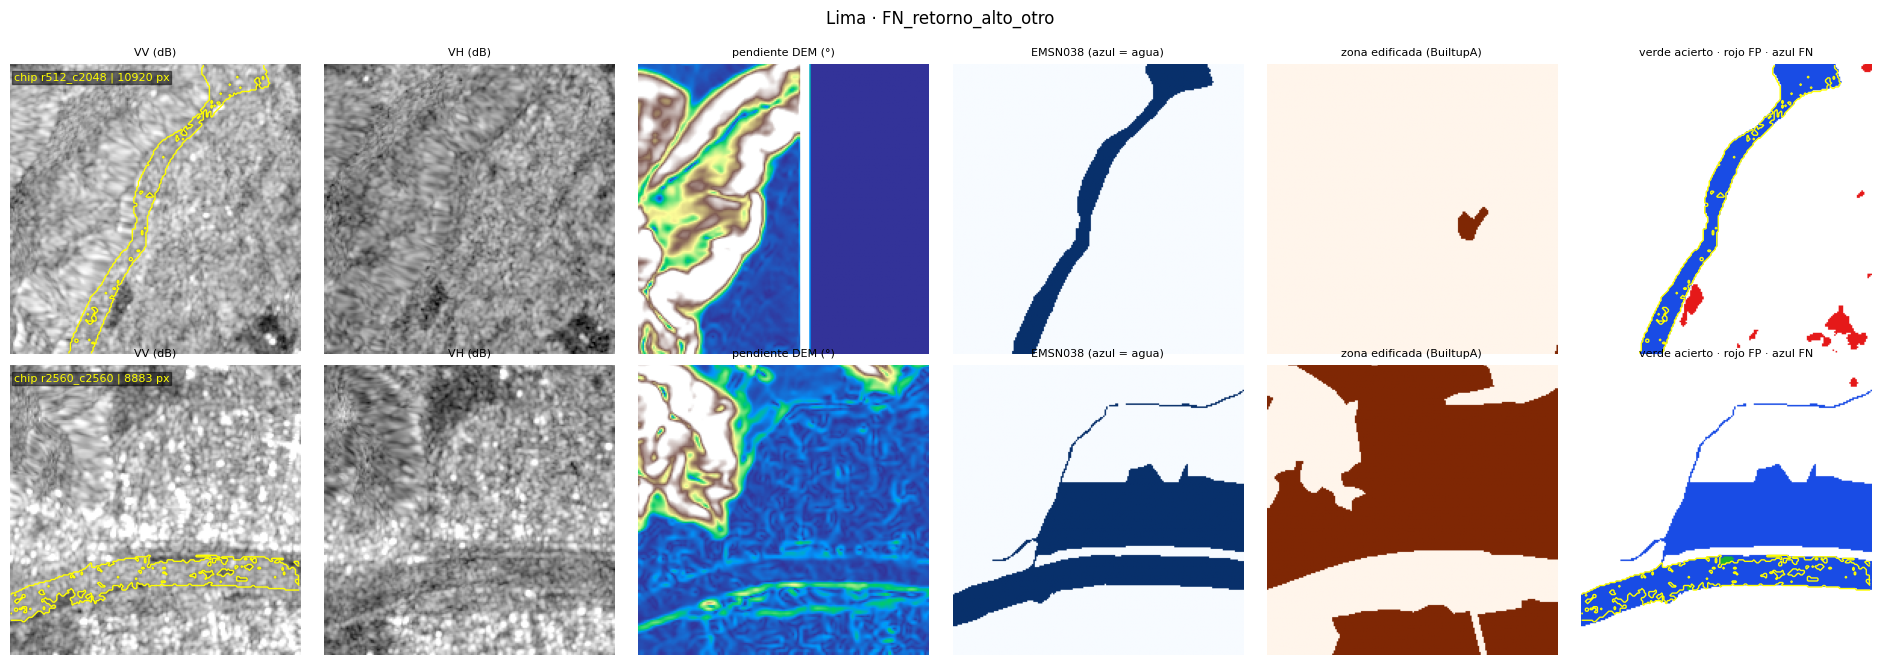

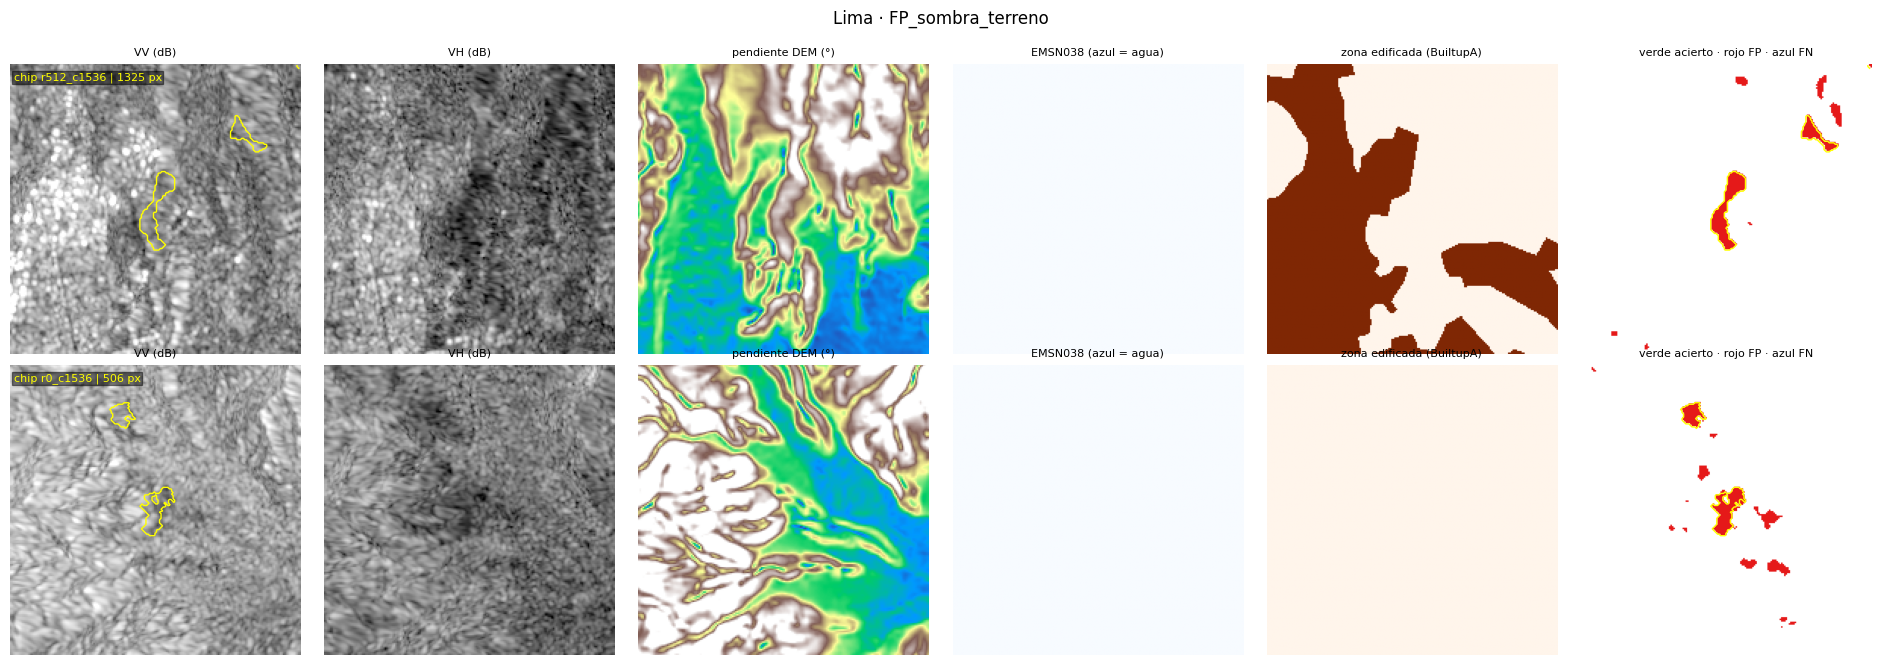

Los FP/FN no asignados a ningún tipo son regiones < 150 px o fuera de las reglas (p. ej. FP en terreno llano no urbano): inspecciónalos en el mosaico del apartado 6 antes de atribuirlos a un mecanismo concreto.


In [ ]:
# ===== Tipos de error en Lima (sombra/pendiente, doble rebote urbano, resto) con paneles =====
EXL, PXL, rowsL = {}, {}, []
for k, rc in enumerate(COMMON):
    types = fd.classify_errors(PRm[k], Lm['Y'][k], Lm['V'][k], Lm['VV'][k], Lm['VH'][k],
                               slope=SL[k] if np.isfinite(SL[k]).any() else None, builtup=BU[k], slope_thr=8.0, vv_bright=-12.0, min_px=150)
    for t, m in types.items():
        n = int(m.sum()); PXL[t] = PXL.get(t, 0) + n
        lst = EXL.setdefault(t, []); lst.append((n, k, m)); lst.sort(key=lambda z: -z[0]); del lst[3:]
FPt, FNt = int(fp_all.sum()), int(fn_all.sum())
for t in sorted(PXL):
    rowsL.append(dict(tipo=t, pixeles=PXL[t], pct_del_FP_o_FN=100 * PXL[t] / (FPt if t.startswith('FP') else FNt)))
tl = pd.DataFrame(rowsL).round(2); display(tl); tl.to_csv(f'{RES}/entregable5_lima_tipos_de_error.csv', index=False)
print(f'FP totales {FPt:,} | FN totales {FNt:,}')

def err_rgb2(pred, y, v):
    e = np.ones(pred.shape + (3,), np.float32); e[y & pred] = (0.1, 0.7, 0.2); e[~y & pred] = (0.9, 0.1, 0.1); e[y & ~pred] = (0.1, 0.3, 0.9); e[~v] = 0.55; return e
for t in sorted(EXL, key=lambda z: -PXL[z]):
    exs = EXL[t][:2]; fig, ax = plt.subplots(len(exs), 6, figsize=(19, 3.3 * len(exs)), squeeze=False)
    for r, (n, k, m) in enumerate(exs):
        r0, r1, c0, c1 = fd.crop_around(m, 192); sl = (slice(r0, r1), slice(c0, c1))
        panels = [(Lm['VV'][k][sl], 'VV (dB)', dict(cmap='gray', vmin=-25, vmax=0)), (Lm['VH'][k][sl], 'VH (dB)', dict(cmap='gray', vmin=-30, vmax=-5)),
                  (SL[k][sl], 'pendiente DEM (°)', dict(cmap='terrain', vmin=0, vmax=30)),
                  (np.ma.masked_where(~Lm['V'][k][sl], Lm['Y'][k][sl]), 'EMSN038 (azul = agua)', dict(cmap='Blues', vmin=0, vmax=1)),
                  (BU[k][sl], 'zona edificada (BuiltupA)', dict(cmap='Oranges', vmin=0, vmax=1)),
                  (err_rgb2(PRm[k], Lm['Y'][k], Lm['V'][k])[sl], 'verde acierto · rojo FP · azul FN', {})]
        for a, (img, ttl, kw) in zip(ax[r], panels):
            a.imshow(img, **kw); a.set_title(ttl, fontsize=8); a.axis('off')
            if ttl.startswith('verde') or ttl.startswith('VV'): a.contour(m[sl].astype(float), [0.5], colors='yellow', linewidths=1)
        ax[r, 0].text(2, 10, f'chip r{COMMON[k][0]}_c{COMMON[k][1]} | {n} px', color='yellow', fontsize=8, bbox=dict(facecolor='black', alpha=.5, pad=1))
    plt.suptitle(f'Lima · {t}', y=1.0); plt.tight_layout(); plt.savefig(f'{RES}/fallos_lima_{t}.png', dpi=170, bbox_inches='tight'); plt.show()
print('Los FP/FN no asignados a ningún tipo son regiones < 150 px o fuera de las reglas (p. ej. FP en terreno llano no urbano): '
      'inspecciónalos en el mosaico del apartado 6 antes de atribuirlos a un mecanismo concreto.')

### Entrega del punto 4 y 5 (Lima): qué debe aparecer en el informe
1. Tabla `entregable4_brecha.csv` + figura `entregable4_brecha.png` (brecha en puntos de IoU y relativa, IC95, línea base Otsu).
2. Justificación de viabilidad (tabla `via`): escena S1 del 17-mar a 1 día de la delineación; la del 29-mar solo como control.
3. **Al menos dos hipótesis** (H1–H3) con su prueba y resultado (`entregable4_H*.csv`, `entregable4_evidencias.csv`), indicando cuáles quedan apoyadas, refutadas o no concluyentes **según las reglas de la tabla de arriba**.
4. Ejemplos visuales de fallos (`fallos_lima_*.png`) junto con los de Sen1Floods11 del notebook 02 (`fallos_*.png`).